# [GSE135022](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE135022)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2020-10-25
> - Modified: 2025-05-17

# 1. Experimental Design

> Global translation during early development depends on the essential transcription factor PRDM10.
> - Han, B.Y., Seah, M.K.Y., Brooks, I.R. et al. Global translation during early development depends on the essential transcription factor PRDM10. Nat Commun 11, 3603 (2020). https://doi.org/10.1038/s41467-020-17304-3.
> - ChIP-seq
> - Illumina NextSeq 500, SE75

| Sample | Organism | Cell | Strain | Treatment |
| - | - | - | - | - |
| Prdm10 WT | Mus musculus | mESC | Prdm10 flox/flox Rosa26-CreERT2 | Ethanol |
| Prdm10-cKO | Mus musculus | mESC | Prdm10 flox/flox Rosa26-CreERT2 | 4-hydroxytamoxifen (4-OHT) |

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicRanges))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(EnrichedHeatmap))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(cowplot))
suppressPackageStartupMessages(library(ggpubr))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/chipseq_Mm_mESC_PRDM10_GSE135022"

gtf_file <- "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf"
blacklist_file <- "~/reference/Database/Blacklist/lists/mm10-blacklist.v2.bed"

suppressPackageStartupMessages(library(BSgenome.Mmusculus.UCSC.mm10))
genome <- BSgenome.Mmusculus.UCSC.mm10

In [3]:
# load reference gene anntotion
gtf <- import(gtf_file) |>
    BRGenomics::tidyChromosomes(keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)

txdb <- txdbmaker::makeTxDbFromGRanges(
    gtf, drop.stop.codons = TRUE, taxonomyId = 10090, 
    metadata = data.frame(
        name = c("Genome", "Gencode Release"),
        value = c("mm10", "vM23")))

Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”


# 2. Data Import

## 1). narrowPeak Import

In [4]:
source("~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_peaks.R")

In [5]:
peaks_files <- file.path(data_dir, "04_output_chipseq", "05_peaks") |>
    list.files(pattern = "\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub(
        "mESC_Prdm10_(.*)_PRDM10_peaks\\.narrowPeak$", "\\1", basename(.x)))

peaks_files <- peaks_files[c(4:6, 1:3)]

paste(names(peaks_files), basename(peaks_files), sep = ": ") |> 
    cat(sep = "\n")

WT_rep1: mESC_Prdm10_WT_rep1_PRDM10_peaks.narrowPeak
WT_rep2: mESC_Prdm10_WT_rep2_PRDM10_peaks.narrowPeak
WT_rep3: mESC_Prdm10_WT_rep3_PRDM10_peaks.narrowPeak
cKO_rep1: mESC_Prdm10_cKO_rep1_PRDM10_peaks.narrowPeak
cKO_rep2: mESC_Prdm10_cKO_rep2_PRDM10_peaks.narrowPeak
cKO_rep3: mESC_Prdm10_cKO_rep3_PRDM10_peaks.narrowPeak


In [6]:
peaks_list <- lapply(
    peaks_files, load_peaks, dropSex = FALSE, blacklist = blacklist_file, 
    verbose = FALSE)

peaks_list[1]

$WT_rep1
GRanges object with 393 ranges and 6 metadata columns:
        seqnames              ranges strand |                   name     score
           <Rle>           <IRanges>  <Rle> |            <character> <numeric>
    [1]     chr1   10037768-10038263      * | mESC_Prdm10_WT_rep1_..      1866
    [2]     chr1   37864558-37864776      * | mESC_Prdm10_WT_rep1_..        87
    [3]     chr1   58392668-58393196      * | mESC_Prdm10_WT_rep1_..      1882
    [4]     chr1   72583172-72583704      * | mESC_Prdm10_WT_rep1_..       955
    [5]     chr1   75479290-75479642      * | mESC_Prdm10_WT_rep1_..       549
    ...      ...                 ...    ... .                    ...       ...
  [389]     chrX 152016525-152017002      * | mESC_Prdm10_WT_rep1_..       154
  [390]     chrX 152368773-152369055      * | mESC_Prdm10_WT_rep1_..       190
  [391]     chrX 160502088-160502515      * | mESC_Prdm10_WT_rep1_..       645
  [392]     chrX 161926316-161926640      * | mESC_Prdm10_WT_rep1_.

## 2). Import bigwig

In [7]:
source("~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_bigwig.R")

In [8]:
signals_files <- file.path(data_dir, "04_output_chipseq", "07_bigwig") |>
    list.files(pattern = ".bw$", full.names = TRUE) |>
    set_names(~ sub(
        pattern = "^mESC_Prdm10_(.*?)(?:_PRDM10)?\\.bw$", 
        replacement = "\\1", x = basename(.x), perl = TRUE
    ))

signals_files <- signals_files[c(5:8, 1:4)]

paste(names(signals_files), basename(signals_files), sep = ": ") |> 
    cat(sep = "\n")

WT_Input: mESC_Prdm10_WT_Input.bw
WT_rep1: mESC_Prdm10_WT_rep1_PRDM10.bw
WT_rep2: mESC_Prdm10_WT_rep2_PRDM10.bw
WT_rep3: mESC_Prdm10_WT_rep3_PRDM10.bw
cKO_Input: mESC_Prdm10_cKO_Input.bw
cKO_rep1: mESC_Prdm10_cKO_rep1_PRDM10.bw
cKO_rep2: mESC_Prdm10_cKO_rep2_PRDM10.bw
cKO_rep3: mESC_Prdm10_cKO_rep3_PRDM10.bw


In [9]:
signals_list <- lapply(
    signals_files, load_bigwig, dropSex = FALSE, blacklist = blacklist_file, 
    verbose = FALSE)

signals_list[1]

$WT_Input
GRanges object with 27571053 ranges and 1 metadata column:
             seqnames            ranges strand |     score
                <Rle>         <IRanges>  <Rle> | <numeric>
         [1]     chr1         1-3000360      * |   0.00000
         [2]     chr1   3000361-3000440      * |   6.41969
         [3]     chr1   3000441-3000630      * |   0.00000
         [4]     chr1   3000631-3000720      * |   6.41969
         [5]     chr1   3000721-3000730      * |   0.00000
         ...      ...               ...    ... .       ...
  [27571049]     chrY 41158621-41158680      * |   6.41969
  [27571050]     chrY 41158681-41158700      * |  12.83940
  [27571051]     chrY 41158701-41158770      * |   6.41969
  [27571052]     chrY 41158771-41158940      * |   0.00000
  [27571053]     chrY 41158941-41159020      * |   6.41969
  -------
  seqinfo: 21 sequences from an unspecified genome


# 3. Quality Control

## 1). Mapping Statistics

| Sample Name | Raw Reads (M) | Clean Reads (M) | Mapped Reads (M) | Mapping Rate | Duplication Rate | Filter Mapped Reads (M) | Filter Mapping Rate | Fragment Length | Number of Peaks | FRIP |
| - | - | - | - | - | - | - | - | - | - | - |
| - | - | - | - | - | - | - | - | - | - | - |

## 2). Number of Peaks

In [10]:
plot_df <- tibble(sample = names(peaks_list)) |>
    separate(
        sample, into = c("Group", "Replicate"), sep = "_", remove = FALSE) |>
    mutate(
        Cell = "mESC", 
        Group = factor(Group, levels = c("WT", "cKO")), 
        Replicate = factor(Replicate), 
        number = lengths(peaks_list)) |>
    arrange(Group, Replicate) |> 
    column_to_rownames("sample")

plot_df

,Group,Replicate,Cell,number
,<fct>,<fct>,<chr>,<int>
WT_rep1,WT,rep1,mESC,393
WT_rep2,WT,rep2,mESC,407
WT_rep3,WT,rep3,mESC,437
cKO_rep1,cKO,rep1,mESC,93
cKO_rep2,cKO,rep2,mESC,109
cKO_rep3,cKO,rep3,mESC,119


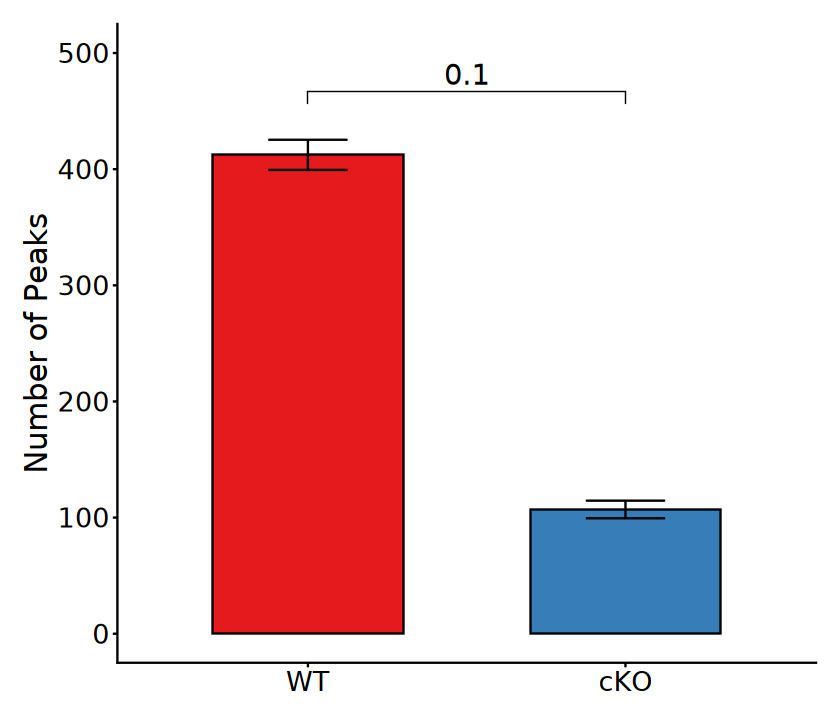

In [11]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = number, fill = Group)) +
    geom_bar(
        stat = "summary", fun = "mean", color = "black", 
        width = 0.6) +
    stat_summary(
        fun.data = mean_se, geom = "errorbar", color = "black", 
        width = 0.25) +
    stat_compare_means(
        comparisons = list(c("cKO", "WT")), method = "wilcox.test", 
        label = "p.format", size = 6, label.y = 450) +
    scale_y_continuous(limits = c(0, 500)) +
    scale_fill_brewer(palette = "Set1") +
    scale_color_brewer(palette = "Set1") +
    labs(x = NULL, y = "Number of Peaks") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "none",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 3). Replicate Consistency

In [12]:
summarize_peak_overlaps <- function(gr_list, group_name = "Group") {
    rep_names <- names(gr_list)

    comb_levels <- unlist(lapply(seq_along(rep_names), function(i) {
        combn(rep_names, i, FUN = paste, collapse = "&")
    }))

    universe <- GenomicRanges::reduce(do.call(c, unname(gr_list)))

    ov_matrix <- map_dfc(
        gr_list, ~ GenomicRanges::countOverlaps(universe, .x) > 0)

    counts_df <- ov_matrix |>
        group_by(across(all_of(rep_names))) |>
        summarise(Counts = n(), .groups = "drop")

    comb_labels <- apply(
        counts_df[, rep_names, drop = FALSE], 1, 
        function(row_vals) {
            paste(rep_names[row_vals], collapse = "&")
    })

    counts_df |>
        mutate(
            Group = group_name,
            Combination = factor(comb_labels, levels = comb_levels)) |>
        filter(Combination != "") |>
        dplyr::select(Group, Combination, Counts) |>
        arrange(Combination) |>
        as.data.frame()
}

In [13]:
replicate_peak_df <- map_df(c("WT", "cKO"), function(grp) {
    message("Processing Group: ", grp)
    sample_names <- grep(
        paste0("^", grp, "_rep"), names(peaks_list), value = TRUE)
    
    gr_sub <- peaks_list[sample_names]
    names(gr_sub) <- str_replace_all(sample_names, paste0("^", grp, "_"), "")
    
    summarize_peak_overlaps(gr_sub, group_name = grp)
}) |>
    mutate(
        Group = factor(Group, c("WT", "cKO")) |>
        forcats::fct_relabel(~ str_replace_all(.x, "_", "\n"))
    )

Processing Group: WT

Processing Group: cKO



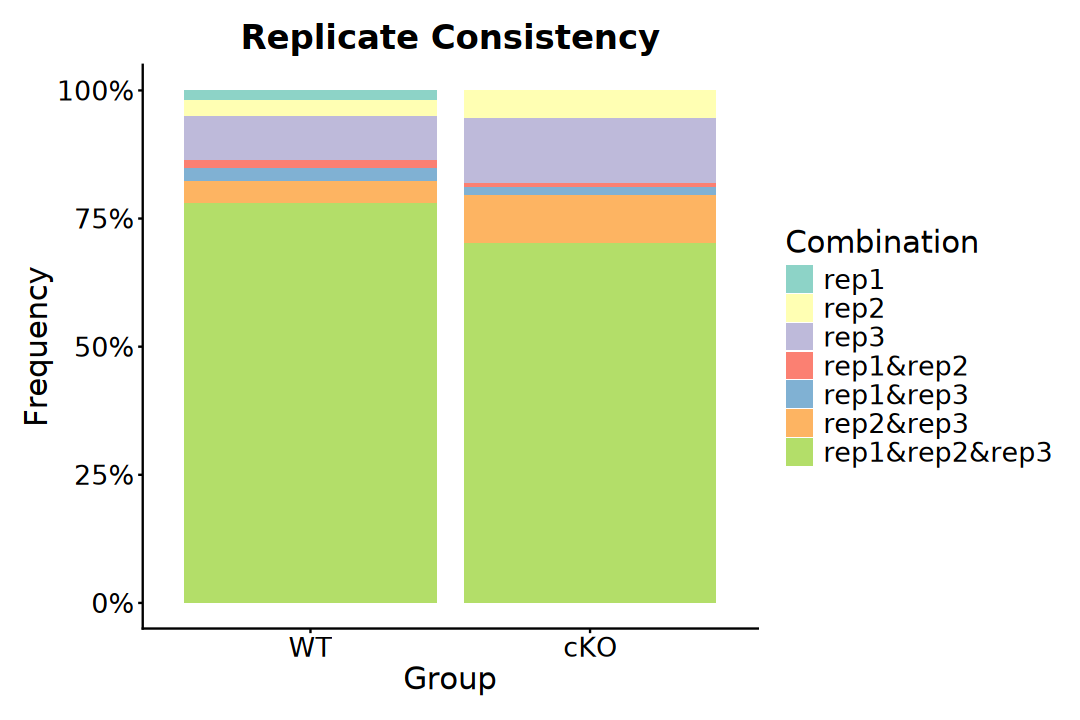

In [14]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(replicate_peak_df, aes(x = Group, y = Counts)) +
    geom_bar(aes(fill = Combination), stat = "identity", position = "fill") +
    scale_y_continuous(labels = scales::percent_format()) + 
    scale_fill_brewer(palette = "Set3") +
    labs(title = "Replicate Consistency", x = "Group", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right", 
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# 4. Genome-wide Landscape

## 1). Global Signal

In [15]:
union_peaks <- do.call(c, unname(peaks_list)) |>
    GenomicRanges::reduce()
union_peaks

GRanges object with 469 ranges and 0 metadata columns:
        seqnames              ranges strand
           <Rle>           <IRanges>  <Rle>
    [1]     chr1   10037768-10038320      *
    [2]     chr1   37864524-37864778      *
    [3]     chr1   45575199-45575522      *
    [4]     chr1   58392668-58393218      *
    [5]     chr1   64733398-64733595      *
    ...      ...                 ...    ...
  [465]     chrX 152016525-152017002      *
  [466]     chrX 152368737-152369092      *
  [467]     chrX 160502059-160502523      *
  [468]     chrX 161926294-161926640      *
  [469]     chrX 164076417-164076694      *
  -------
  seqinfo: 20 sequences from an unspecified genome; no seqlengths

In [16]:
# ~ 10 minutes, 32G memory
bin_means_df <- purrr::map(signals_files, function(file) {
    import(BigWigFile(file), which = union_peaks, as = "NumericList") |>
        mean(na.rm = TRUE) |>
        tidyr::replace_na(0)
}) |> as.data.frame()

In [17]:
head(bin_means_df)

,WT_Input,WT_rep1,WT_rep2,WT_rep3,cKO_Input,cKO_rep1,cKO_rep2,cKO_rep3
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1.776154,177.08546,156.33018,158.06729,2.466566,9.720893,12.7964366,10.213125
2,3.449010,33.94509,33.03124,44.09399,3.070313,2.680956,0.4381687,6.458986
3,2.417291,18.23533,39.02442,41.17939,6.720757,4.472500,7.5485000,1.330942
4,2.982653,198.56380,239.33124,253.56736,5.550492,7.635271,18.9376167,13.435031
5,8.105676,33.08566,13.16040,44.77202,5.498799,6.787440,1.4107704,5.444773
6,2.516142,106.50329,108.76095,138.33997,5.870185,10.872878,17.0532808,16.059067


In [18]:
bin_means_df <- as.data.frame(union_peaks) |>
    cbind(bin_means_df[names(signals_list)]) |>
    filter(apply(pick(all_of(names(signals_list))), 1, var) > 0)

In [19]:
cor_mat <- cor(bin_means_df[names(signals_list)], method = "spearman")

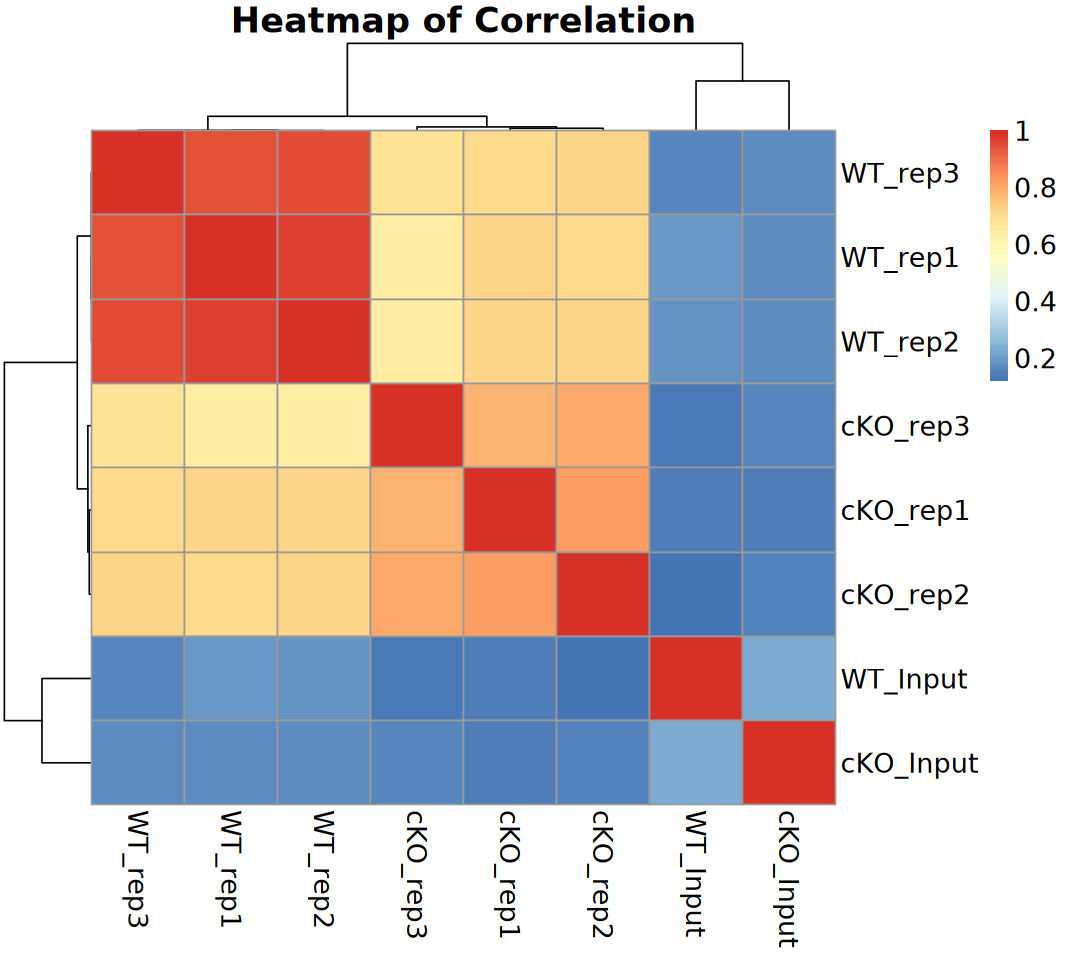

In [20]:
options(repr.plot.width = 9, repr.plot.height = 8)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation", 
    clustering_distance_cols = "correlation", 
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = TRUE, show_rownames = TRUE)

In [21]:
pca_df <- bin_means_df[, names(signals_list)] |> t() |>
    prcomp(center = TRUE, scale. = TRUE)

per_var <- round(pca_df$sdev^2 / sum(pca_df$sdev^2) * 100, 2)

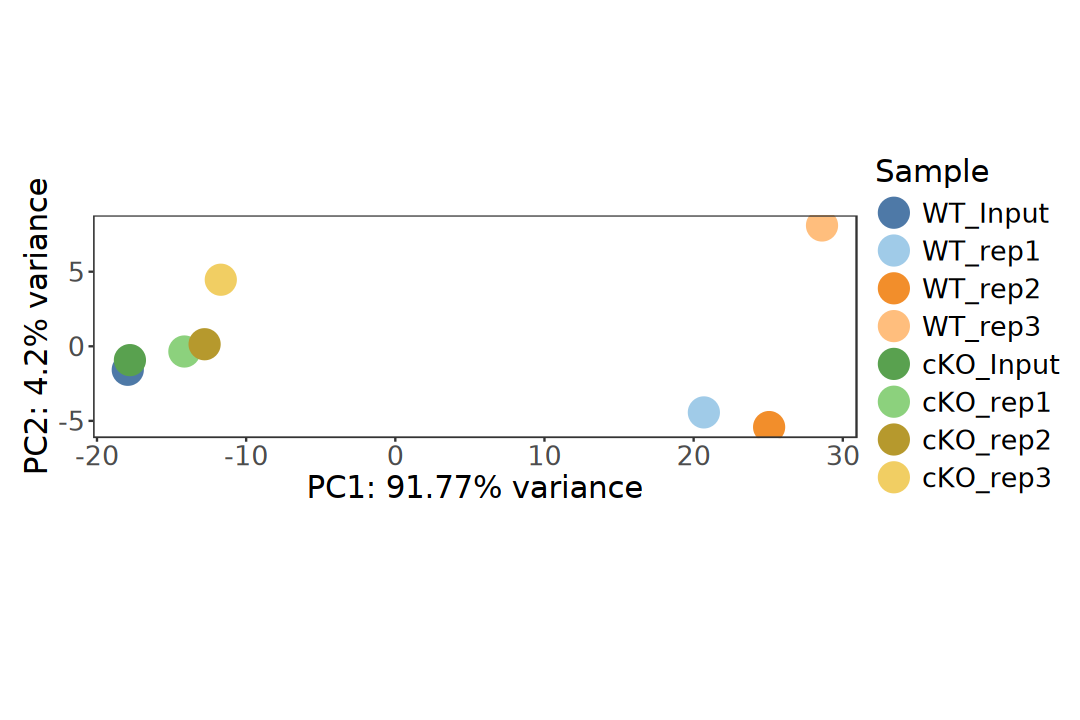

In [22]:
options(repr.plot.width = 9, repr.plot.height = 6)

pca_df$x |> as.data.frame() |> 
    rownames_to_column(var = "Sample") |>
    mutate(Sample = factor(Sample, levels = names(signals_list))) |>
ggplot(aes(PC1, PC2)) +
    geom_point(aes(color = Sample), size = 8) +
    coord_fixed() +
    ggthemes::scale_color_tableau(palette = "Tableau 20") +
    xlab(paste0("PC1: ", per_var[1], "% variance")) +
    ylab(paste0("PC2: ", per_var[2], "% variance")) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "right",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). Metagene Profile

In [23]:
suppressPackageStartupMessages(library(EnrichedHeatmap))

In [24]:
GENES <- gtf |> subset(
    type == "gene" & gene_type == "protein_coding", 
    select = c("gene_id", "gene_name", "gene_type")
)

In [25]:
# ~ 10 minutes
gene_mat_list <- lapply(
    signals_list, normalizeToMatrix, GENES, value_column = "score", 
    mean_mode = "w0", extend = 2000, w = 50, smooth = FALSE, 
    target_ratio = 0.4, background = NA)

In [26]:
max_signal <- unlist(gene_mat_list, use.names = FALSE) |>
    abs() |> quantile(0.99, na.rm = TRUE)

unified_cols <- circlize::colorRamp2(
    c(0, max_signal), c("#F5F5F5", "#FF3F56"))

In [27]:
# ==============================================================================
# ⚠️ WARNING / IMPORTANT NOTE:
# With the current settings, the row order (gene/peak order) across different 
# heatmaps is INCONSISTENT. Each heatmap calculates its own hierarchical 
# clustering independently based on its input matrix. If you want to visually 
# compare rows across different groups, you must enforce a unified row order 
# by setting 'cluster_rows = FALSE' and providing a fixed 'row_order'.
# ==============================================================================

ht_list <- lapply(seq_along(gene_mat_list), function(idx) {
    mark <- names(gene_mat_list)[idx]
    EnrichedHeatmap(
        gene_mat_list[[idx]], 
        name = mark, 
        column_title = mark, 
        col = unified_cols, 
        width = unit(4, "cm"), 
        show_row_names = FALSE, 
        axis_name = c("-2kb", "TSS", "TES", "+2kb"), 
        top_annotation = HeatmapAnnotation(
            enriched = anno_enriched(
                gp = gpar(lwd = 2, col = "black"), 
                ylim = c(3, 7), 
                axis_param = list(gp = gpar(fontsize = 10))), 
            height = unit(3, "cm"), 
            show_legend = FALSE), 
        heatmap_legend_param = list(
            title = "Signal p-value", 
            direction = "horizontal", 
            title_position = "topcenter", 
            legend_width = unit(4, "cm")), 
        use_raster = TRUE)
})

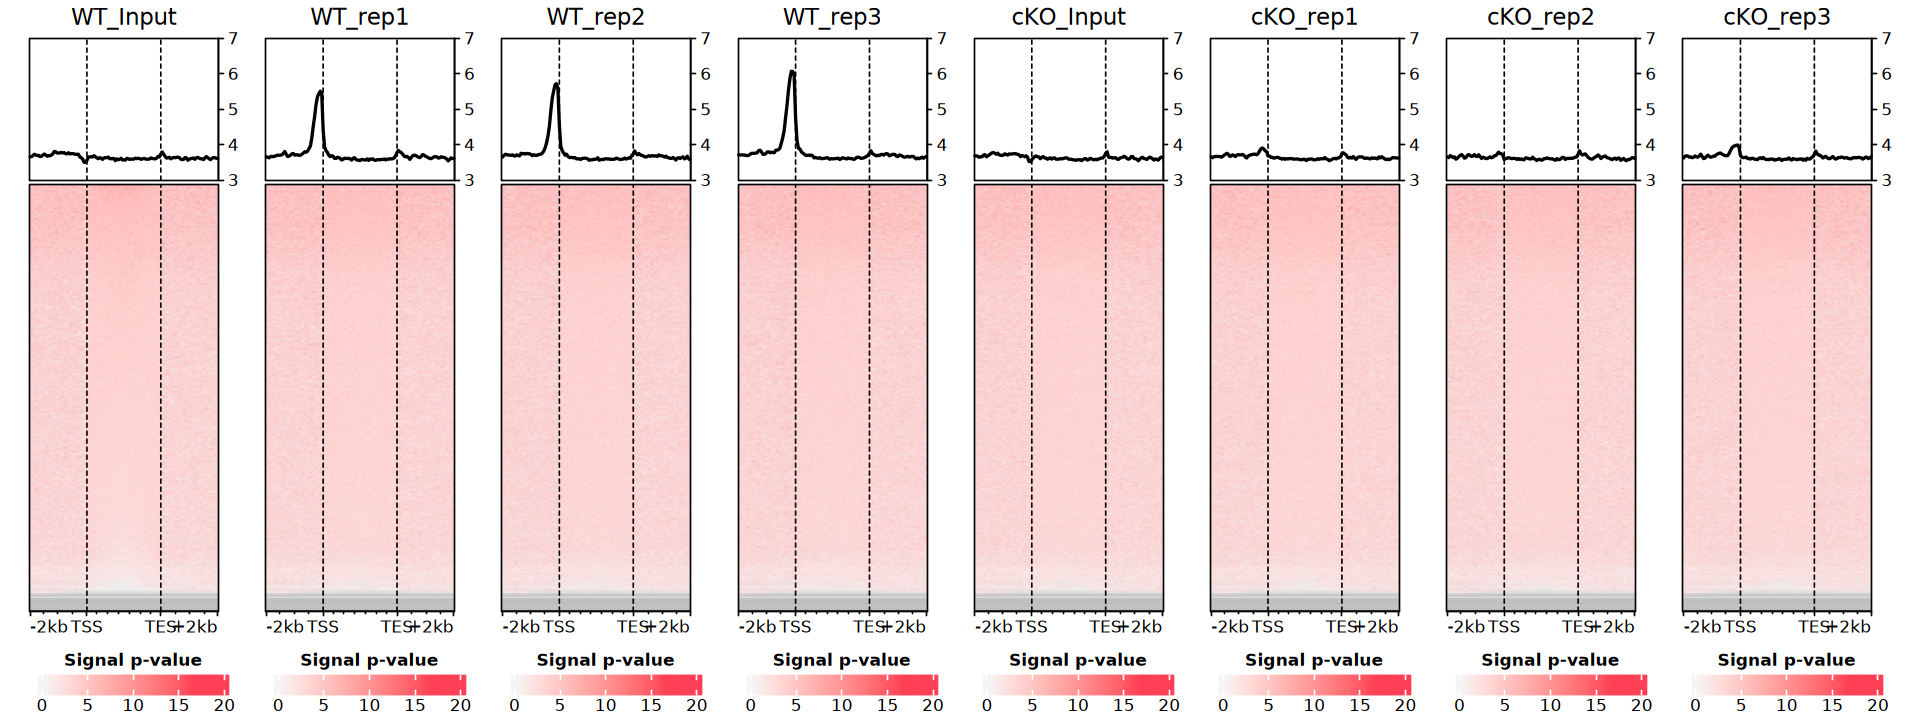

In [28]:
options(repr.plot.width = 16, repr.plot.height = 6)

draw(
    Reduce(`+`, ht_list), 
    heatmap_legend_side = "bottom", 
    ht_gap = unit(10, "mm"), 
    legend_gap = unit(10, "mm")
)

# 5. Peaks Annotation

In [29]:
suppressPackageStartupMessages(library(ChIPseeker))

In [30]:
peaks_anno_list <- lapply(
    peaks_list, annotatePeak, tssRegion = c(-2000, 500), 
    TxDb = txdb, level = "transcript", verbose = FALSE, 
    genomicAnnotationPriority = c(
        "Promoter", "5UTR", "3UTR", "Exon", "Intron", 
        "Downstream", "Intergenic")
)

>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...
>> Using Genome: mm10 ...


Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ChIPseeker package.
  Please report the issue at <https://github.com/YuLab-SMU/ChIPseeker/issues>.”


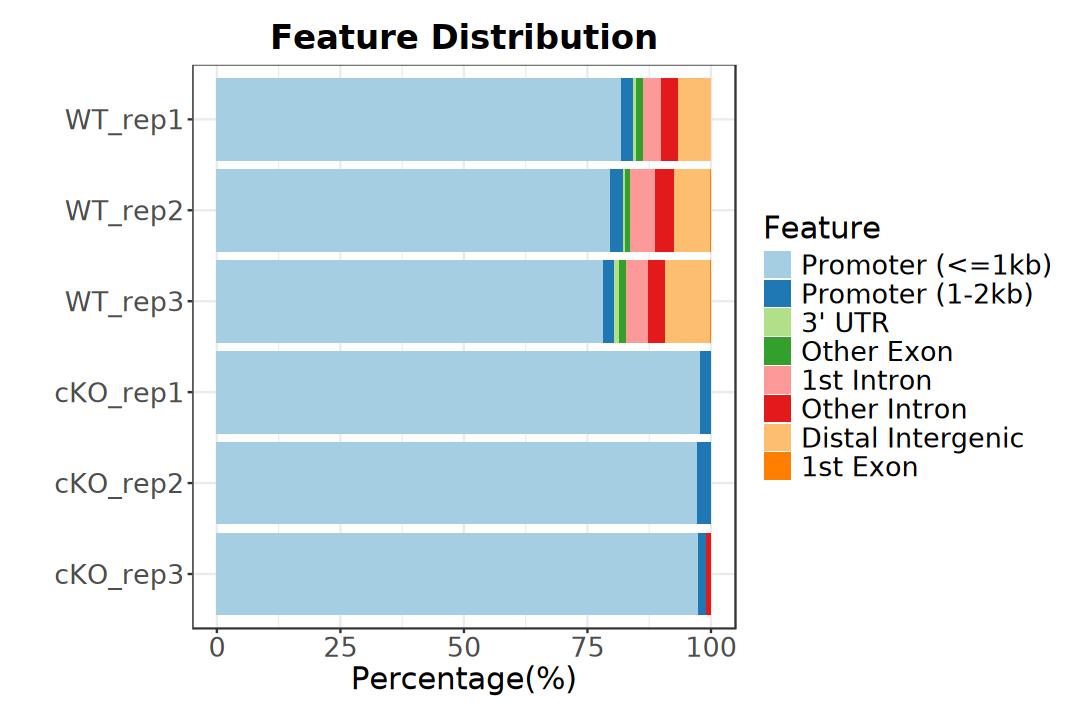

In [31]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotAnnoBar(peaks_anno_list) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [32]:
peaks_anno_list[[1]]@anno |> head()

GRanges object with 6 ranges and 15 metadata columns:
      seqnames            ranges strand |                   name     score
         <Rle>         <IRanges>  <Rle> |            <character> <numeric>
  [1]     chr1 10037768-10038263      * | mESC_Prdm10_WT_rep1_..      1866
  [2]     chr1 37864558-37864776      * | mESC_Prdm10_WT_rep1_..        87
  [3]     chr1 58392668-58393196      * | mESC_Prdm10_WT_rep1_..      1882
  [4]     chr1 72583172-72583704      * | mESC_Prdm10_WT_rep1_..       955
  [5]     chr1 75479290-75479642      * | mESC_Prdm10_WT_rep1_..       549
  [6]     chr1 86442424-86442679      * | mESC_Prdm10_WT_rep1_..        83
      signalValue    pValue    qValue      peak        annotation   geneChr
        <numeric> <numeric> <numeric> <integer>       <character> <integer>
  [1]    42.29820  192.0740 186.64900       267  Promoter (<=1kb)         1
  [2]     6.67381   13.0353   8.70411       135  Promoter (<=1kb)         1
  [3]    43.08620  193.6660 188.22600     

In [33]:
peaks_anno_list <- lapply(peaks_anno_list, function(anno) {
    anno@anno |> 
    as.data.frame() |>
    mutate(
        Category = case_when(
            grepl("Promoter", annotation) ~ "Promoter",
            grepl("UTR|Exon", annotation) ~ "Exon",
            grepl("Intron", annotation) ~ "Intron",
            grepl("Downstream|Intergenic", annotation) ~ "Intergenic",
            TRUE ~ as.character(annotation)
        )) |> 
    as("GRanges")
})

In [34]:
promoter_genes <- lapply(peaks_anno_list, function(anno) {
    anno |> as.data.frame() |>
        filter(Category == "Promoter", !is.na(geneId), geneId != "") |>
        distinct(geneId) |>
        pull(geneId) |>
        unique()
})

In [35]:
suppressPackageStartupMessages(library(UpSetR))

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”


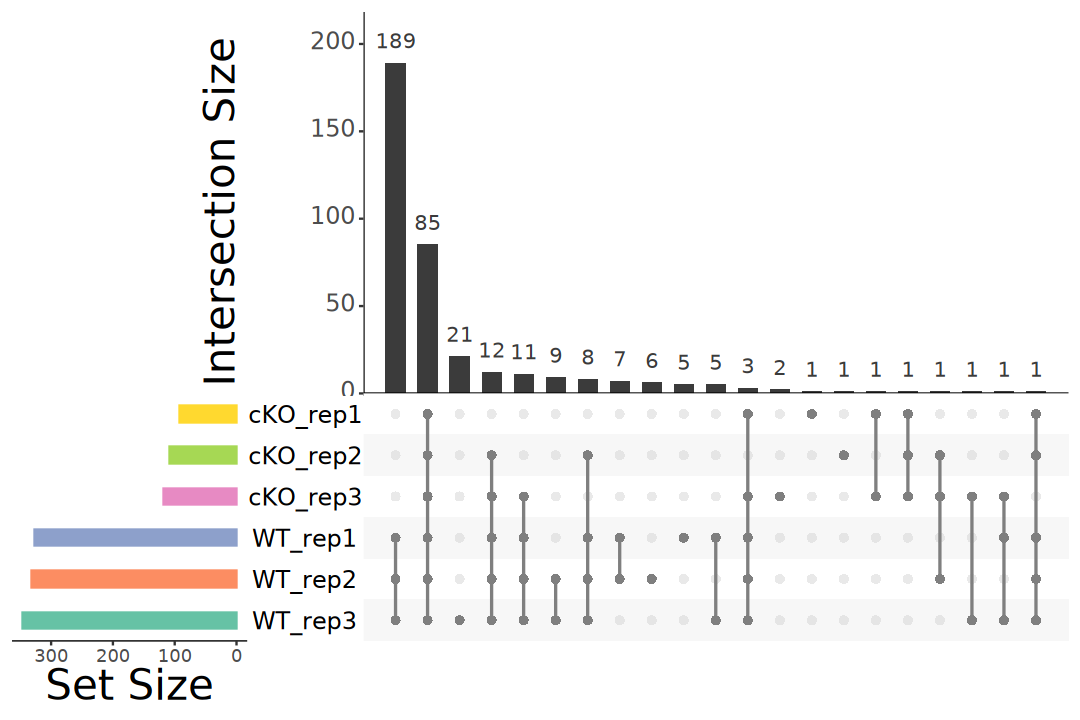

In [36]:
options(repr.plot.width = 9, repr.plot.height = 6)

UpSetR::upset(
    fromList(promoter_genes), nsets = length(promoter_genes), 
    mb.ratio = c(0.55, 0.45), order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = length(promoter_genes), name = "Set2"),
    matrix.color = "grey50", text.scale = c(3, 2, 3, 1.5, 2, 2))

# 6. Function Analysis

In [37]:
suppressPackageStartupMessages(library(ChIPseeker))
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [38]:
wt_genes  <- promoter_genes[grep("^WT_", names(promoter_genes))]
cko_genes <- promoter_genes[grep("^cKO_", names(promoter_genes))]

wt_shared <- Reduce(intersect, wt_genes)
cko_shared <- Reduce(intersect, cko_genes)
wt_specific <- setdiff(wt_shared, cko_shared)

promoter_subsets <- list(
    WT_shared = wt_shared, cKO_shared = cko_shared, WT_specific = wt_specific)

str(promoter_subsets)

List of 3
 $ WT_shared  : chr [1:309] "ENSMUSG00000025917.9" "ENSMUSG00000060771.14" "ENSMUSG00000051223.14" "ENSMUSG00000039354.16" ...
 $ cKO_shared : chr [1:86] "ENSMUSG00000033557.17" "ENSMUSG00000015305.6" "ENSMUSG00000019777.16" "ENSMUSG00000019818.15" ...
 $ WT_specific: chr [1:224] "ENSMUSG00000025917.9" "ENSMUSG00000060771.14" "ENSMUSG00000051223.14" "ENSMUSG00000039354.16" ...


In [39]:
add_ENTREZID <- function(
    query_ids, orgdb, fromType = "ENSEMBL", toType = c("SYMBOL", "ENTREZID"), 
    ignoreVersion = FALSE) {

    if(fromType == "ENSEMBL" & ignoreVersion) {
        query_ids <- sub("\\..*$", "", query_ids) |> unique()
    }

    gene_map <- clusterProfiler::bitr(
        query_ids, OrgDb = orgdb, fromType = fromType, toType = toType, 
        drop = FALSE)

    idx <- match(query_ids, gene_map[[fromType]])

    res <- data.frame(
        fromType = query_ids, stringsAsFactors = FALSE)

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }

    return(res)
}

In [40]:
promoter_subsets <- lapply(promoter_subsets, add_ENTREZID,
    orgdb = org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), 
    ignoreVersion = TRUE)

'select()' returned 1:1 mapping between keys and columns

Warning message in clusterProfiler::bitr(query_ids, OrgDb = orgdb, fromType = fromType, :
“3.24% of input gene IDs are fail to map...”
'select()' returned 1:1 mapping between keys and columns

'select()' returned 1:1 mapping between keys and columns

Warning message in clusterProfiler::bitr(query_ids, OrgDb = orgdb, fromType = fromType, :
“4.46% of input gene IDs are fail to map...”


In [41]:
genes_list <- lapply(promoter_subsets, \(x) x$SYMBOL |> na.omit() |> unique())

all_symbols <- AnnotationDbi::keys(org.Mm.eg.db, keytype = "SYMBOL")

In [42]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, universe = all_symbols, 
    OrgDb = org.Mm.eg.db, ont = "ALL", keyType = 'SYMBOL', 
    pAdjustMethod = "BH", pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

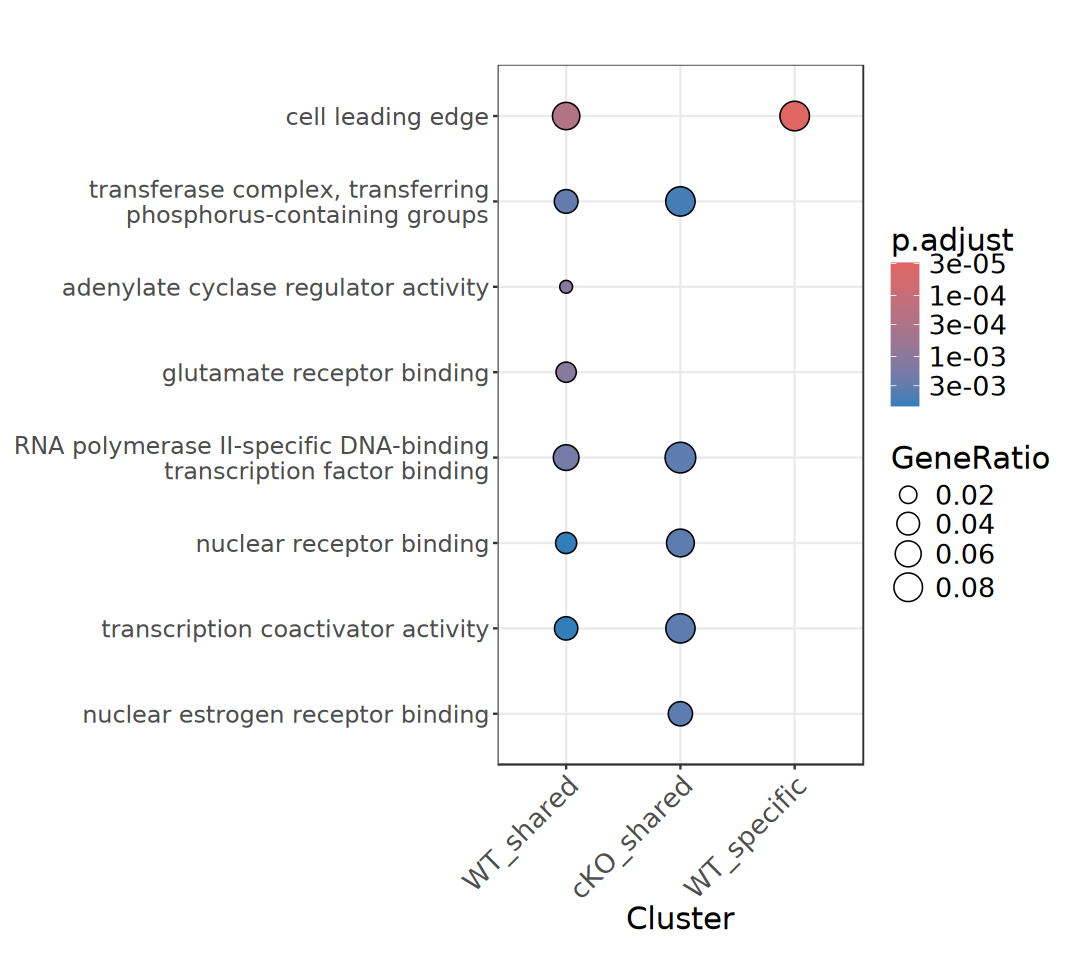

In [43]:
options(repr.plot.width = 9, repr.plot.height = 8)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [44]:
genes_list <- lapply(promoter_subsets, \(x) x$ENTREZID |> na.omit() |> unique())

all_entrezid <- AnnotationDbi::keys(org.Mm.eg.db, keytype = "ENTREZID")

In [45]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, universe = all_entrezid, 
    organism = "mmu", 
    pAdjustMethod = "BH", pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

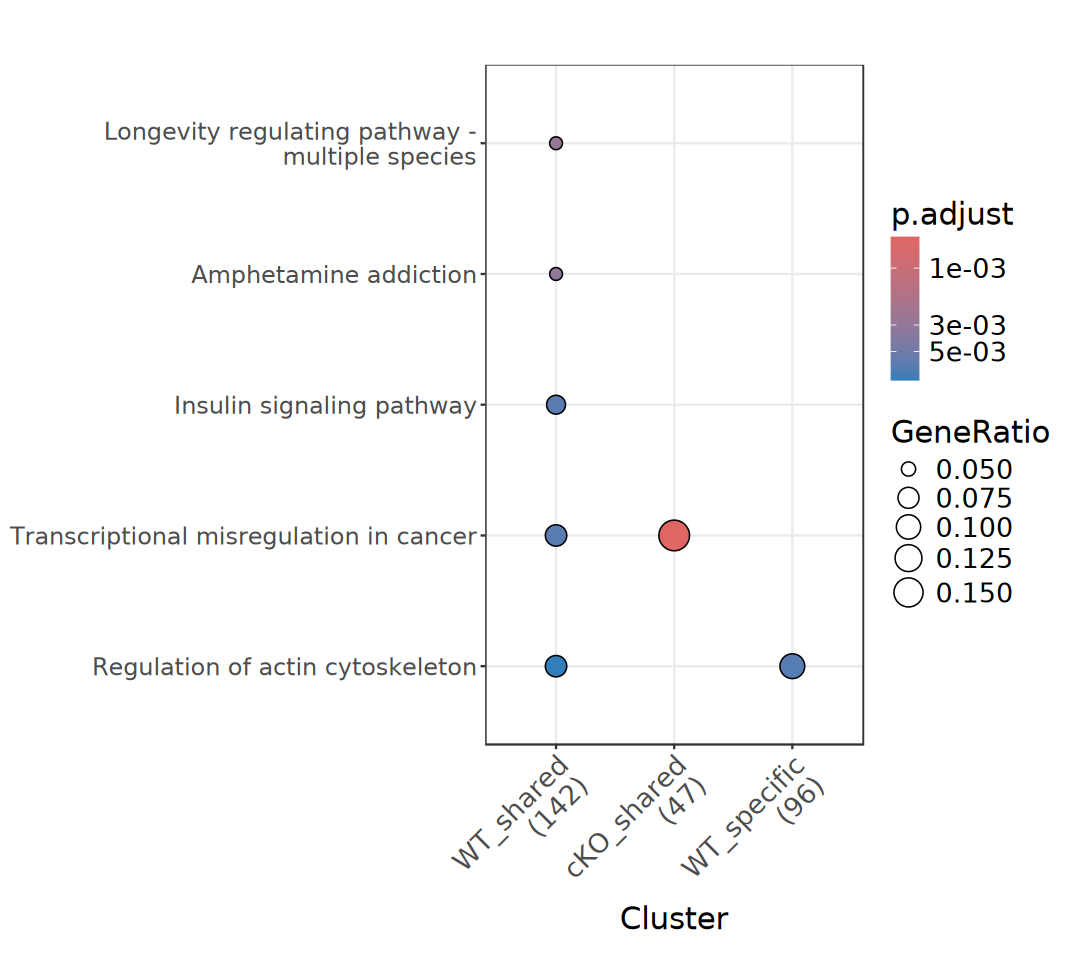

In [46]:
options(repr.plot.width = 9, repr.plot.height = 8)

dotplot(ekegg_compare, showCategory = 5, label_format = 40) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

# * Reference